# Lab 4 – Partea 2: arhitecturi convoluționale, pooling și recurență

Acest notebook implementează cerințele Părții 2 din `lab4_ML.pdf` și reutilizează infrastructura existentă din `src/lab4_common.py`.

Experimentele acoperite:
1. **1–6 straturi convoluționale**, cu și fără pooling;
2. comparația numărului de filtre și a **1–3 straturi fully connected**;
3. comparația CNN fără recurență cu CNN+**LSTM** și CNN+**GRU**;
4. macro-F1, număr de parametri, timp de antrenare și dimensiunea modelului;
5. curbe train/validation loss și macro-F1, matrici de confuzie și interpretarea rezultatelor;
6. alegerea arhitecturii de bază pentru Partea 3.

**Important:** notebook-ul folosește direct `lab4_common.make_config`, `lab4_common.run_experiment`, `lab4_common.load_log`, `lab4_common.load_history`, `lab4_common.load_predictions`, `lab4_common.plot_history` și `lab4_common.plot_confusion`. Astfel, păstrează exact protocolul comun: aceleași date, normalizare, augmentare, fold-uri stratificate (seed 42), antrenare și format de salvare.

Nu este necesar să rulezi notebook-ul Părții 1. Este necesar ca `src/lab4_common.py` și datasetul Flowers să fie disponibile în proiect.

In [1]:
# 0. Importuri și localizarea proiectului
import sys
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Caută rădăcina proiectului (folderul care conține pyproject.toml).
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Nu am găsit pyproject.toml. Deschide notebook-ul din rădăcina repository-ului "
        "sau dintr-un subfolder al acestuia."
    )

SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import lab4_common

DEVICE = lab4_common.get_device()
print("Rădăcina proiectului:", ROOT)
print("Dataset:", lab4_common.DATA_DIR)
print("Rezultate:", lab4_common.OUT_DIR)
print("Device:", DEVICE)
print("Clase:", lab4_common.CLASSES)

Rădăcina proiectului: D:\uni_ 3\ML\lab_1
Dataset: D:\uni_ 3\ML\lab_1\data\raw\flower_photos
Rezultate: D:\uni_ 3\ML\lab_1\results\lab4
Device: cpu
Clase: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


## 1. Verificarea datelor și a fold-urilor comune

`run_experiment` încarcă datasetul și folosește fold-urile comune din `results/lab4/folds.csv`. În această celulă verificăm că imaginile pot fi găsite și că împărțirea are cele 5 fold-uri cerute.

In [2]:
df, X, y = lab4_common.load_dataset(img_size=64)
folds = lab4_common.get_folds(df)

assert len(df) == len(X) == len(y) == len(folds)
assert set(folds) == {0, 1, 2, 3, 4}

print(f"Număr imagini: {len(df)}")
print(f"Forma tensorului X: {tuple(X.shape)}")
print(f"Fold-uri: {sorted(set(folds))}")
display(df["class"].value_counts().sort_index().rename("număr imagini").to_frame())
display(pd.crosstab(df["class"], folds, rownames=["clasă"], colnames=["fold"]))

Număr imagini: 3670
Forma tensorului X: (3670, 3, 64, 64)
Fold-uri: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,număr imagini
class,
daisy,633
dandelion,898
roses,641
sunflowers,699
tulips,799


fold,0,1,2,3,4
clasă,,,,,
daisy,127,127,127,126,126
dandelion,180,179,179,180,180
roses,128,129,128,128,128
sunflowers,140,139,140,140,140
tulips,159,160,160,160,160


## 2. Configurația comună și funcția pentru experimente

În `lab4_common.py`, `conv_layers` este o listă în care fiecare element reprezintă numărul de filtre al unui strat convoluțional. `pooling` acceptă `"max"`, `"avg"` sau `None`. Pentru experimentele de aici păstrăm constante setările care nu sunt investigate: kernel 3, stride 1, ReLU, fără batch normalization și dropout, Adam cu learning rate 0.001, batch size 64, maximum 30 epoci și patience 5.

Fiecare experiment are un nume unic cu prefixul `p2_`, pentru a putea separa rezultatele Părții 2 de experimentele celorlalte părți.

In [3]:
COMMON_SETTINGS = {
    "img_size": 64,
    "kernel_size": 3,
    "stride": 1,
    "activation": "relu",
    "batch_norm": False,
    "dropout": 0.0,
    "augment": True,
    "optimizer": "adam",
    "lr": 1e-3,
    "weight_decay": 0.0,
    "l1": 0.0,
    "batch_size": 64,
    "epochs": 30,
    "patience": 5,
}

def make_p2_config(name, conv_layers, pooling, fc_layers=(128,), recurrent=None):
    return lab4_common.make_config(
        name=name,
        conv_layers=list(conv_layers),
        pooling=pooling,
        fc_layers=list(fc_layers),
        recurrent=recurrent,
        **COMMON_SETTINGS
    )

def run_p2_experiment(name, conv_layers, pooling, fc_layers=(128,), recurrent=None):
    cfg = make_p2_config(name, conv_layers, pooling, fc_layers, recurrent)
    print("\n" + "=" * 80)
    print("Experiment:", name)
    print("Config:", {k: cfg[k] for k in [
        "conv_layers", "pooling", "fc_layers", "recurrent",
        "activation", "batch_norm", "dropout", "lr"
    ]})
    return lab4_common.run_experiment(cfg, device=DEVICE, verbose=True)

## 3. Grid arhitectural: 1–6 straturi convoluționale, cu/fără pooling

Se variază adâncimea de la 1 la 6 straturi convoluționale și se compară două variante:
- max-pooling după fiecare strat convoluțional;
- fără pooling.

Numărul de filtre este menținut la 32 pe fiecare strat, iar clasificatorul final are un strat ascuns de 128 neuroni. Astfel, comparația izolează efectul adâncimii și al pooling-ului.

In [4]:
depth_experiments = {}

for depth in range(1, 7):
    for pooling_name, pooling_value in [("maxpool", "max"), ("nopool", None)]:
        name = f"p2_depth{depth}_{pooling_name}"
        depth_experiments[name] = {
            "conv_layers": [32] * depth,
            "pooling": pooling_value,
            "fc_layers": [128],
            "recurrent": None,
        }

for name, cfg in depth_experiments.items():
    run_p2_experiment(
        name,
        cfg["conv_layers"],
        cfg["pooling"],
        cfg["fc_layers"],
        cfg["recurrent"]
    )


Experiment: p2_depth1_maxpool
Config: {'conv_layers': [32], 'pooling': 'max', 'fc_layers': [128], 'recurrent': None, 'activation': 'relu', 'batch_norm': False, 'dropout': 0.0, 'lr': 0.001}
[p2_depth1_maxpool] fold 0 pe cpu ...
  fold 0 epoca  1: loss 1.703/1.245  F1 0.329/0.487  (1s)
  fold 0 epoca  2: loss 1.193/1.227  F1 0.504/0.448  (2s)
  fold 0 epoca  3: loss 1.125/1.075  F1 0.549/0.589  (3s)
  fold 0 epoca  4: loss 1.078/1.016  F1 0.577/0.610  (4s)
  fold 0 epoca  5: loss 1.029/1.008  F1 0.585/0.593  (5s)
  fold 0 epoca  6: loss 0.998/0.960  F1 0.603/0.627  (6s)
  fold 0 epoca  7: loss 0.965/0.935  F1 0.616/0.639  (7s)
  fold 0 epoca  8: loss 0.931/0.900  F1 0.630/0.646  (8s)
  fold 0 epoca  9: loss 0.902/0.900  F1 0.645/0.650  (9s)
  fold 0 epoca 10: loss 0.900/0.884  F1 0.649/0.662  (10s)
  fold 0 epoca 11: loss 0.882/0.913  F1 0.643/0.650  (11s)
  fold 0 epoca 12: loss 0.843/0.872  F1 0.681/0.666  (12s)
  fold 0 epoca 13: loss 0.867/0.886  F1 0.668/0.644  (13s)
  fold 0 epoca

## 4. Comparația numărului de filtre

Se păstrează 3 straturi convoluționale, max-pooling și un strat fully connected cu 128 neuroni. Se compară 16, 32 și 64 filtre pe strat. Configurația cu 32 filtre este deja inclusă în experimentul `p2_depth3_maxpool`, deci nu este antrenată din nou.

In [5]:
filter_experiments = {}

for n_filters in [16, 32, 64]:
    name = f"p2_filters{n_filters}"
    filter_experiments[name] = {
        "conv_layers": [n_filters] * 3,
        "pooling": "max",
        "fc_layers": [128],
        "recurrent": None,
    }

# Refolosim rezultatul deja calculat pentru 3 straturi, 32 filtre, max-pooling.
filter_experiments["p2_filters32"]["reuse_name"] = "p2_depth3_maxpool"

for name, cfg in filter_experiments.items():
    if "reuse_name" in cfg:
        print(f"{name}: configurație identică cu {cfg['reuse_name']}; nu repetăm antrenarea.")
        continue
    run_p2_experiment(
        name,
        cfg["conv_layers"],
        cfg["pooling"],
        cfg["fc_layers"],
        cfg["recurrent"]
    )


Experiment: p2_filters16
Config: {'conv_layers': [16, 16, 16], 'pooling': 'max', 'fc_layers': [128], 'recurrent': None, 'activation': 'relu', 'batch_norm': False, 'dropout': 0.0, 'lr': 0.001}
[p2_filters16] fold 0 pe cpu ...
  fold 0 epoca  1: loss 1.433/1.198  F1 0.334/0.482  (1s)
  fold 0 epoca  2: loss 1.169/1.117  F1 0.498/0.541  (1s)
  fold 0 epoca  3: loss 1.112/1.082  F1 0.541/0.560  (2s)
  fold 0 epoca  4: loss 1.068/1.076  F1 0.552/0.540  (2s)
  fold 0 epoca  5: loss 1.022/1.002  F1 0.590/0.605  (3s)
  fold 0 epoca  6: loss 0.997/0.996  F1 0.602/0.591  (3s)
  fold 0 epoca  7: loss 0.975/0.965  F1 0.610/0.608  (4s)
  fold 0 epoca  8: loss 0.941/0.934  F1 0.628/0.645  (4s)
  fold 0 epoca  9: loss 0.899/0.932  F1 0.653/0.600  (5s)
  fold 0 epoca 10: loss 0.893/0.922  F1 0.657/0.603  (6s)
  fold 0 epoca 11: loss 0.872/0.857  F1 0.660/0.673  (6s)
  fold 0 epoca 12: loss 0.854/0.823  F1 0.656/0.677  (7s)
  fold 0 epoca 13: loss 0.830/0.842  F1 0.682/0.676  (7s)
  fold 0 epoca 14: l

## 5. Comparația numărului de straturi fully connected

Se păstrează partea convoluțională de referință: 3 straturi convoluționale, 32 filtre pe strat și max-pooling. Se compară clasificatoare cu 1, 2 și 3 straturi fully connected ascunse. Experimentul cu un singur strat dens este deja inclus în `p2_depth3_maxpool`.

In [6]:
fc_experiments = {
    "p2_fc1": [128],
    "p2_fc2": [256, 128],
    "p2_fc3": [256, 128, 64],
}

for name, fc_layers in fc_experiments.items():
    if name == "p2_fc1":
        print("p2_fc1: configurație identică cu p2_depth3_maxpool; nu repetăm antrenarea.")
        continue
    run_p2_experiment(
        name,
        conv_layers=[32, 32, 32],
        pooling="max",
        fc_layers=fc_layers,
        recurrent=None
    )

p2_fc1: configurație identică cu p2_depth3_maxpool; nu repetăm antrenarea.

Experiment: p2_fc2
Config: {'conv_layers': [32, 32, 32], 'pooling': 'max', 'fc_layers': [256, 128], 'recurrent': None, 'activation': 'relu', 'batch_norm': False, 'dropout': 0.0, 'lr': 0.001}
[p2_fc2] fold 0 pe cpu ...
  fold 0 epoca  1: loss 1.396/1.196  F1 0.376/0.448  (1s)
  fold 0 epoca  2: loss 1.158/1.127  F1 0.497/0.472  (2s)
  fold 0 epoca  3: loss 1.119/1.049  F1 0.522/0.572  (3s)
  fold 0 epoca  4: loss 1.018/0.973  F1 0.587/0.593  (4s)
  fold 0 epoca  5: loss 0.934/0.938  F1 0.619/0.627  (6s)
  fold 0 epoca  6: loss 0.873/0.889  F1 0.666/0.634  (7s)
  fold 0 epoca  7: loss 0.849/0.828  F1 0.678/0.673  (8s)
  fold 0 epoca  8: loss 0.816/0.834  F1 0.677/0.679  (9s)
  fold 0 epoca  9: loss 0.795/0.894  F1 0.684/0.614  (10s)
  fold 0 epoca 10: loss 0.770/0.786  F1 0.692/0.685  (11s)
  fold 0 epoca 11: loss 0.748/0.816  F1 0.712/0.672  (12s)
  fold 0 epoca 12: loss 0.733/0.777  F1 0.710/0.691  (13s)
  fold

## 6. Recurență: CNN vs CNN+LSTM vs CNN+GRU

Se păstrează aceeași parte convoluțională (3 straturi, 32 filtre, max-pooling) și același clasificator fully connected (128 neuroni). Se compară:
- CNN fără strat recurent;
- CNN cu LSTM;
- CNN cu GRU.

În implementarea comună, LSTM/GRU citește harta de trăsături rând cu rând.

In [7]:
recurrent_experiments = {
    "p2_cnn_lstm": "lstm",
    "p2_cnn_gru": "gru",
}

for name, recurrent_type in recurrent_experiments.items():
    run_p2_experiment(
        name,
        conv_layers=[32, 32, 32],
        pooling="max",
        fc_layers=[128],
        recurrent=recurrent_type
    )

print("Varianta CNN fără recurență este reprezentată de p2_depth3_maxpool.")


Experiment: p2_cnn_lstm
Config: {'conv_layers': [32, 32, 32], 'pooling': 'max', 'fc_layers': [128], 'recurrent': 'lstm', 'activation': 'relu', 'batch_norm': False, 'dropout': 0.0, 'lr': 0.001}
[p2_cnn_lstm] fold 0 pe cpu ...
  fold 0 epoca  1: loss 1.466/1.271  F1 0.335/0.450  (1s)
  fold 0 epoca  2: loss 1.197/1.152  F1 0.480/0.466  (2s)
  fold 0 epoca  3: loss 1.116/1.096  F1 0.529/0.527  (4s)
  fold 0 epoca  4: loss 1.055/0.992  F1 0.564/0.579  (5s)
  fold 0 epoca  5: loss 0.996/0.980  F1 0.607/0.582  (6s)
  fold 0 epoca  6: loss 0.956/0.932  F1 0.604/0.608  (7s)
  fold 0 epoca  7: loss 0.921/0.899  F1 0.632/0.650  (9s)
  fold 0 epoca  8: loss 0.878/0.847  F1 0.661/0.677  (10s)
  fold 0 epoca  9: loss 0.852/0.850  F1 0.668/0.679  (11s)
  fold 0 epoca 10: loss 0.836/0.850  F1 0.675/0.671  (12s)
  fold 0 epoca 11: loss 0.817/0.825  F1 0.680/0.670  (14s)
  fold 0 epoca 12: loss 0.788/0.869  F1 0.686/0.655  (15s)
  fold 0 epoca 13: loss 0.788/0.821  F1 0.690/0.664  (16s)
  fold 0 epoca

## 7. Tabel comparativ pentru toate experimentele Părții 2

`load_log()` citește rezultatele complete salvate de infrastructura comună. Tabelul este filtrat la experimentele cu prefix `p2_` și include macro-F1 mediu ± deviație standard, timpul total de antrenare, numărul de parametri și dimensiunea modelului salvat.

In [4]:
log = lab4_common.load_log()
if log.empty:
    raise RuntimeError("Nu există experimente complete în log. Rulează celulele de experimente.")

p2_results = log[log["name"].str.startswith("p2_")].copy()
if p2_results.empty:
    raise RuntimeError("Nu au fost găsite experimente cu prefixul p2_.")

columns_to_show = [
    "name", "val_f1_mean", "val_f1_std", "best_epoch_mean",
    "train_minutes_total", "n_params", "model_mb"
]
display(p2_results[columns_to_show].sort_values("val_f1_mean", ascending=False).round(4))

,name,val_f1_mean,val_f1_std,best_epoch_mean,train_minutes_total,n_params,model_mb
0,p2_filters64,0.7667,0.0119,25.4,6.0081,600709,2.2958
1,p2_depth6_maxpool,0.7389,0.0136,28.6,3.0880,52005,0.2045
2,p2_fc2,0.7367,0.0221,25.6,2.6692,577477,2.2070
3,p2_depth2_maxpool,0.7357,0.0114,25.6,2.4911,1059493,4.0454
4,p2_depth5_maxpool,0.7337,0.0067,28.2,2.7862,55045,0.2156
5,p2_fc3,0.7282,0.0247,21.8,2.4564,585413,2.2377
6,p2_depth3_maxpool,0.7278,0.0233,20.8,2.2716,282309,1.0813
7,p2_depth6_nopool,0.7269,0.0138,22.6,18.0815,16825125,64.1888
8,p2_cnn_gru,0.7264,0.0098,24.6,2.9485,184773,0.7101
9,p2_depth4_maxpool,0.7246,0.0147,22.2,2.3202,94949,0.3672


## 8. Grafice comparative: performanță, complexitate și timp

Graficele compară macro-F1 pe cele 5 fold-uri, numărul de parametri și timpul total de antrenare. Timpii sunt măsurați pe dispozitivul afișat în prima celulă; comparațiile de timp sunt relevante în cadrul aceleiași rulări și aceluiași dispozitiv.

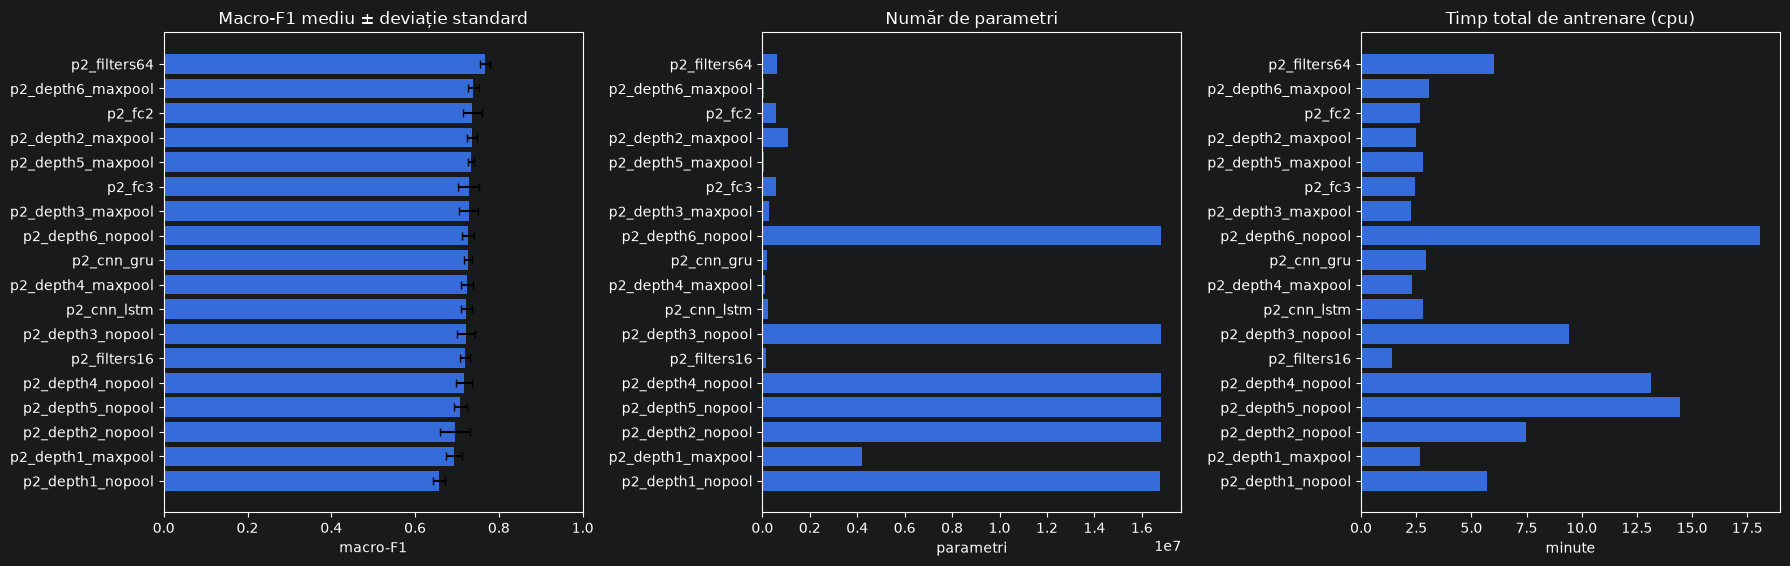

In [5]:
plot_df = p2_results.sort_values("val_f1_mean", ascending=True)

fig, axes = plt.subplots(1, 3, figsize=(18, max(5, 0.32 * len(plot_df))))

axes[0].barh(
    plot_df["name"], plot_df["val_f1_mean"],
    xerr=plot_df["val_f1_std"], capsize=3
)
axes[0].set(title="Macro-F1 mediu ± deviație standard", xlabel="macro-F1")
axes[0].set_xlim(0, 1)

axes[1].barh(plot_df["name"], plot_df["n_params"])
axes[1].set(title="Număr de parametri", xlabel="parametri")

axes[2].barh(plot_df["name"], plot_df["train_minutes_total"])
axes[2].set(title=f"Timp total de antrenare ({DEVICE})", xlabel="minute")

plt.tight_layout()
plt.show()

## 9. Curbe train/validation loss și macro-F1 + matrici de confuzie

Pentru fiecare experiment se afișează curbele medii pe fold-uri și matricea de confuzie construită din predicțiile out-of-fold. Fiecare imagine este astfel evaluată în fold-ul în care a fost ținută pentru validare.


 p2_filters64


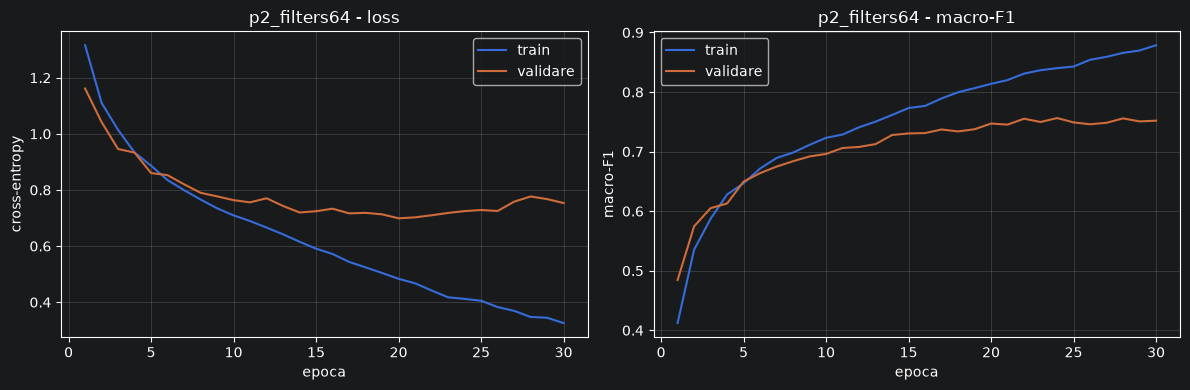

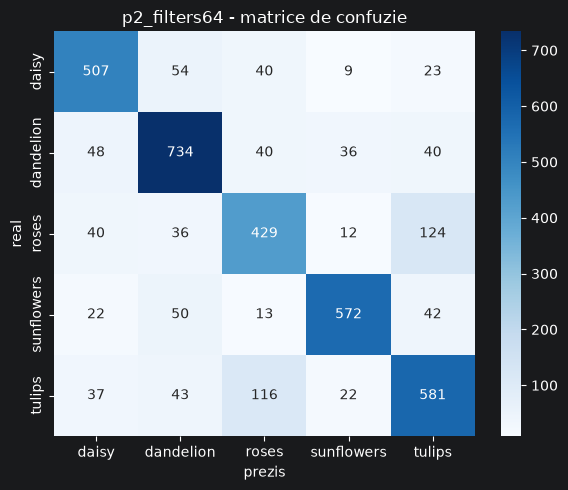


 p2_depth6_maxpool


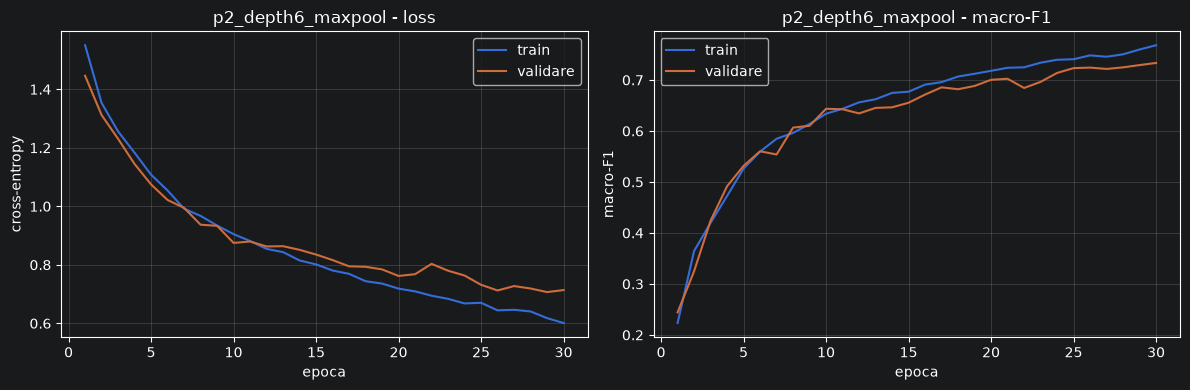

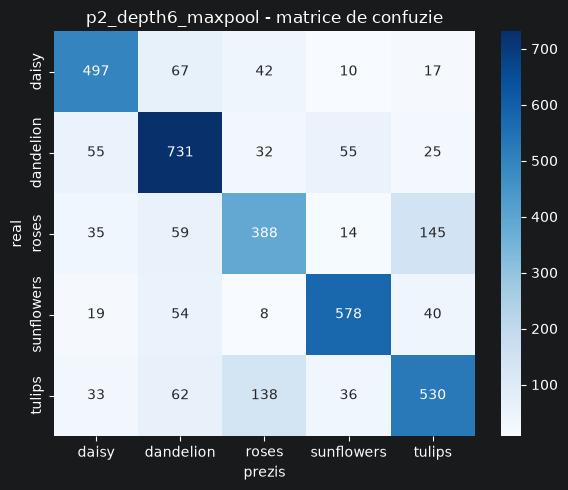


 p2_fc2


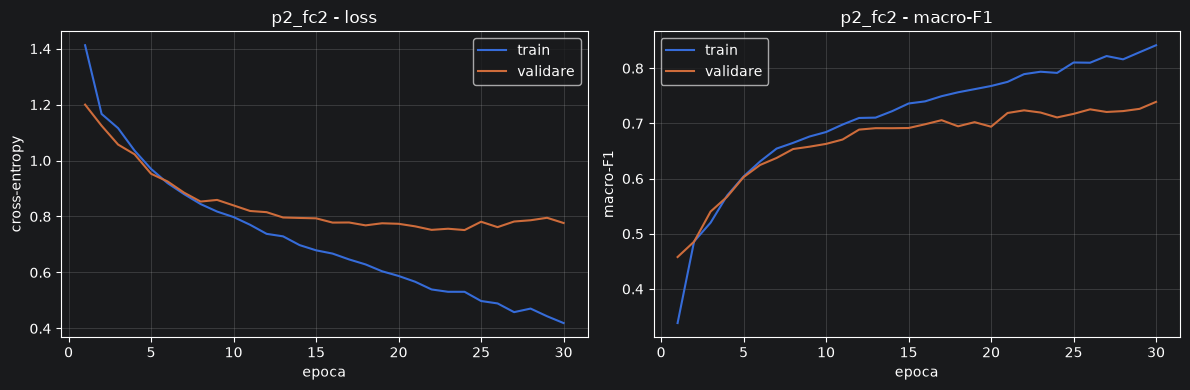

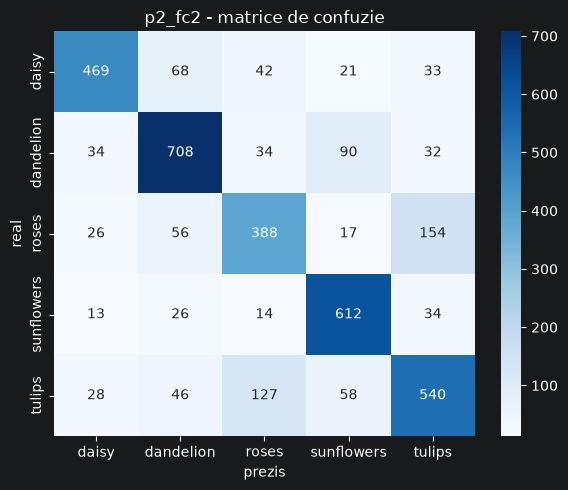


 p2_depth2_maxpool


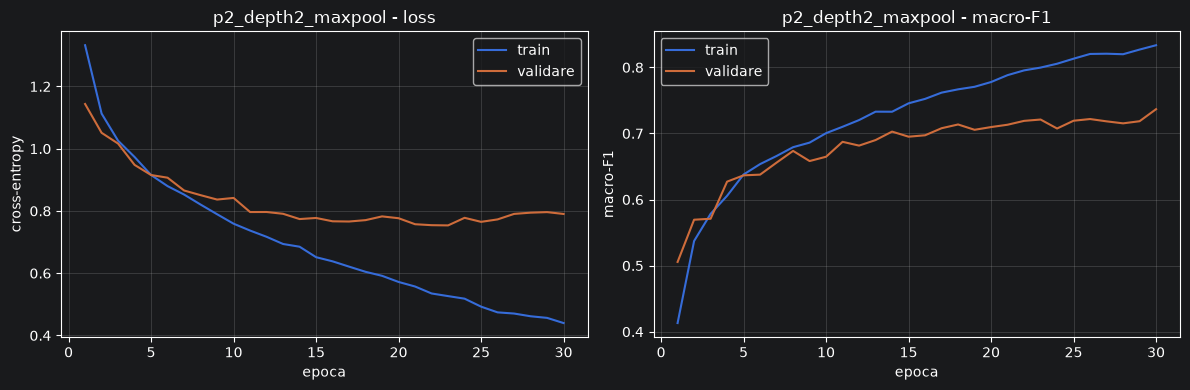

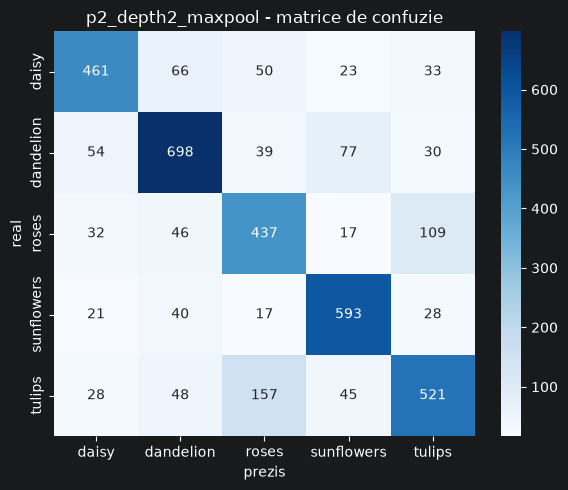


 p2_depth5_maxpool


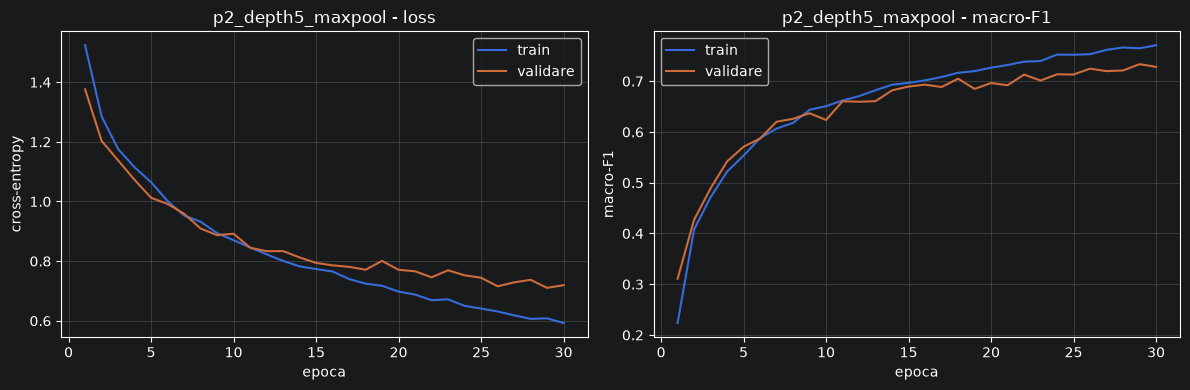

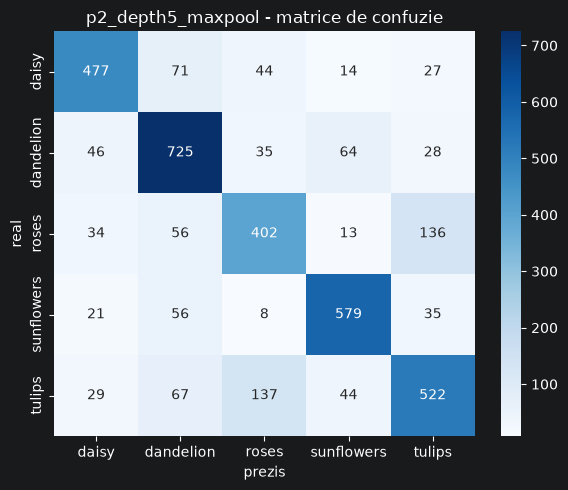


 p2_fc3


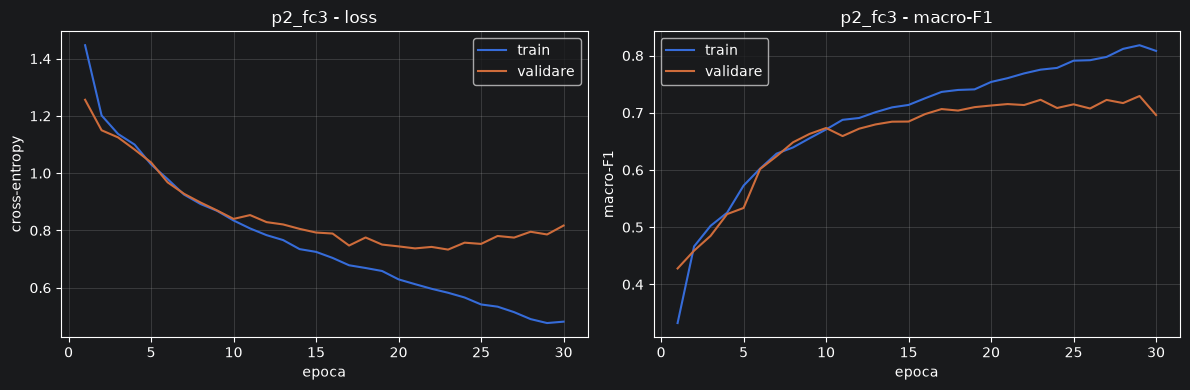

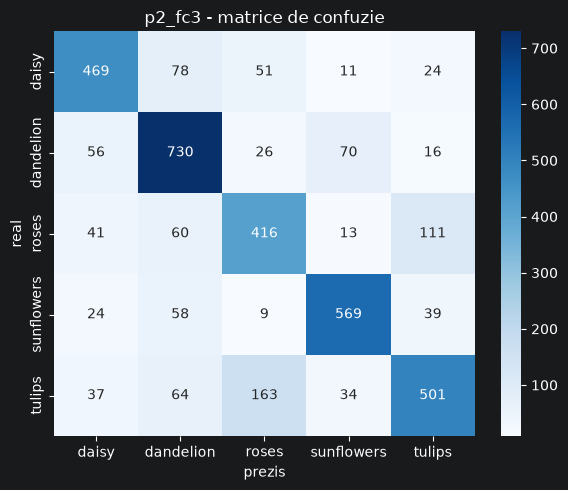


 p2_depth3_maxpool


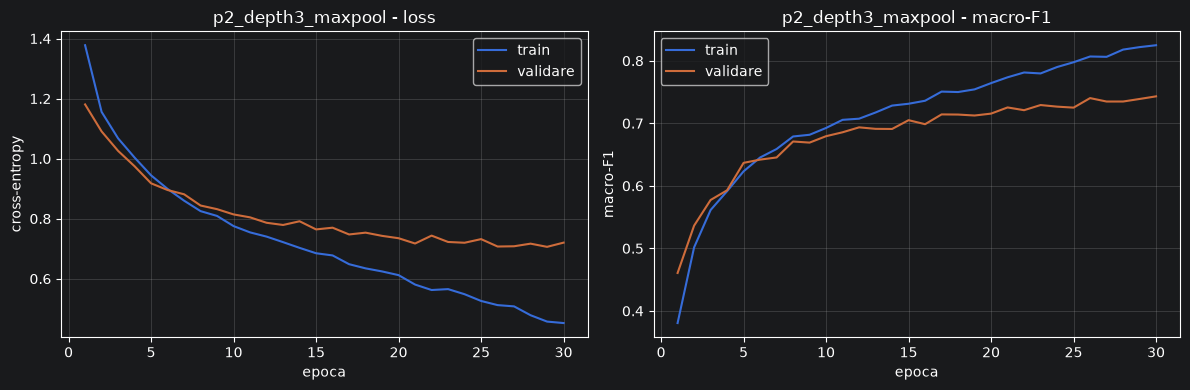

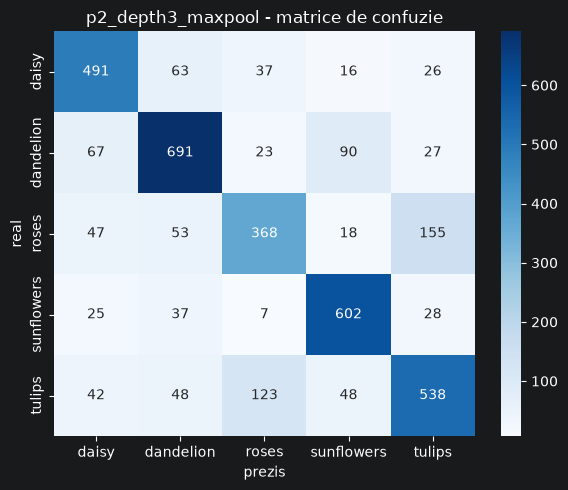


 p2_depth6_nopool


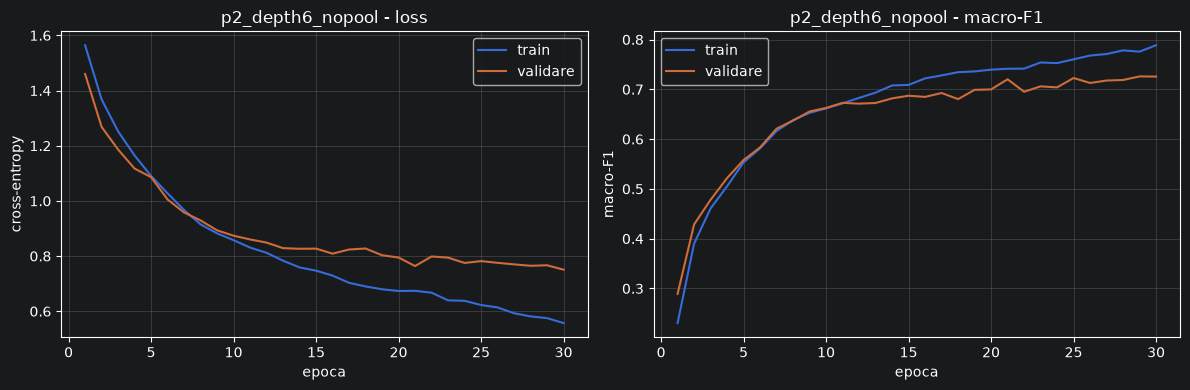

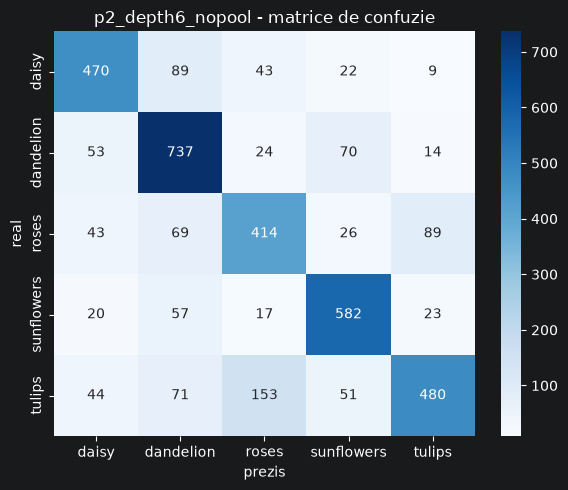


 p2_cnn_gru


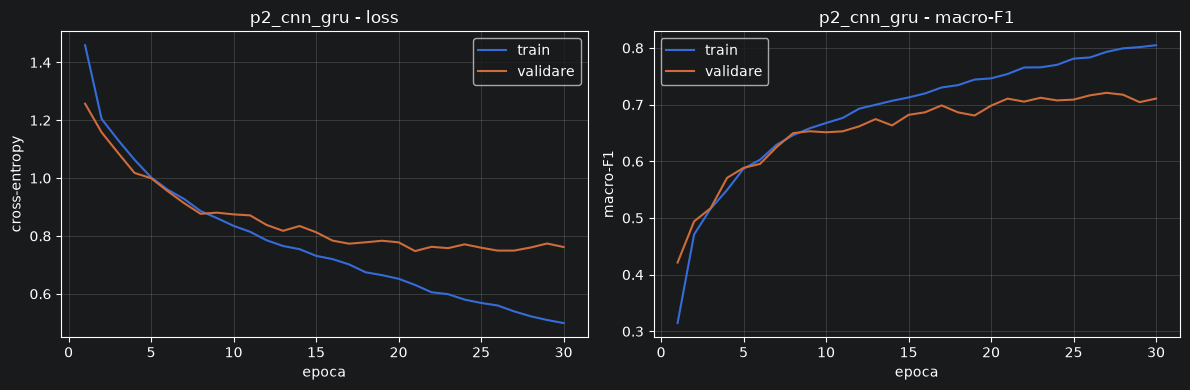

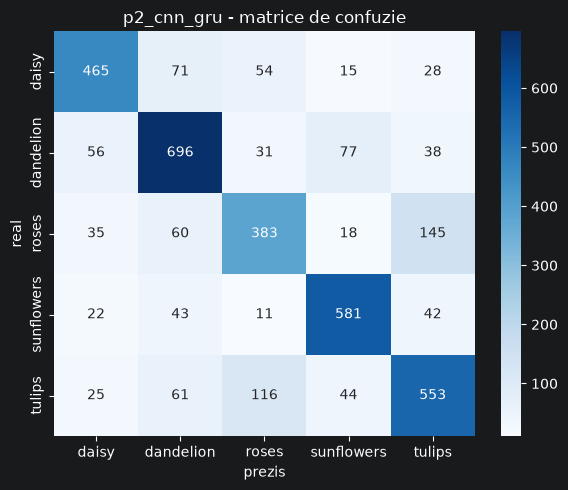


 p2_depth4_maxpool


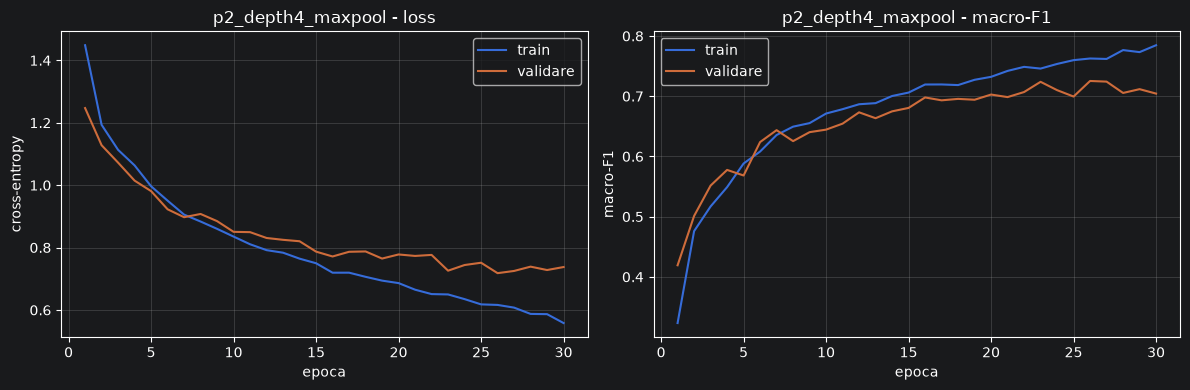

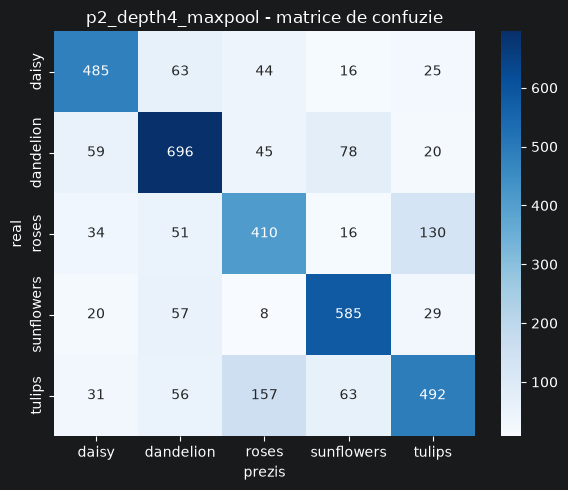


 p2_cnn_lstm


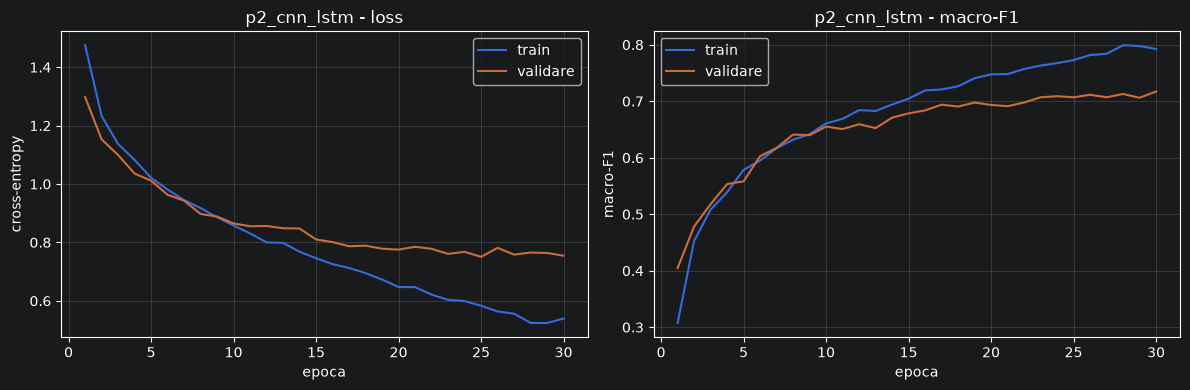

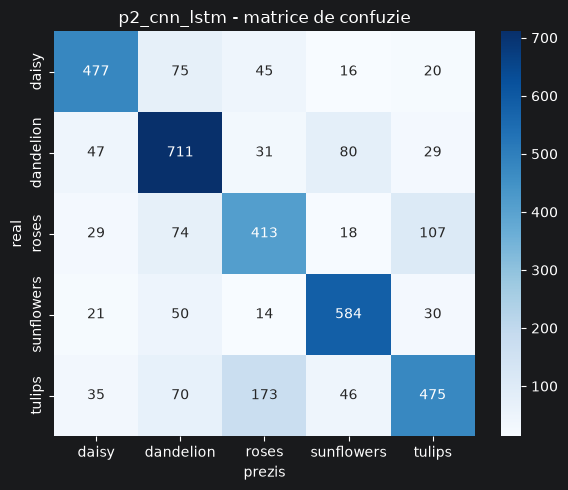


 p2_depth3_nopool


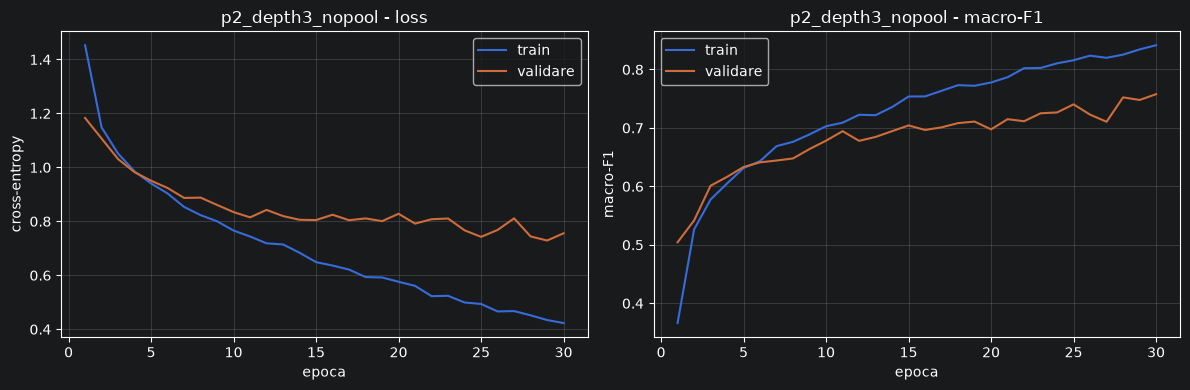

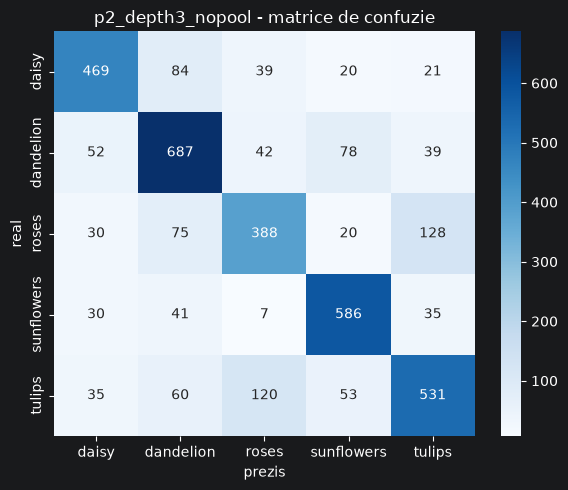


 p2_filters16


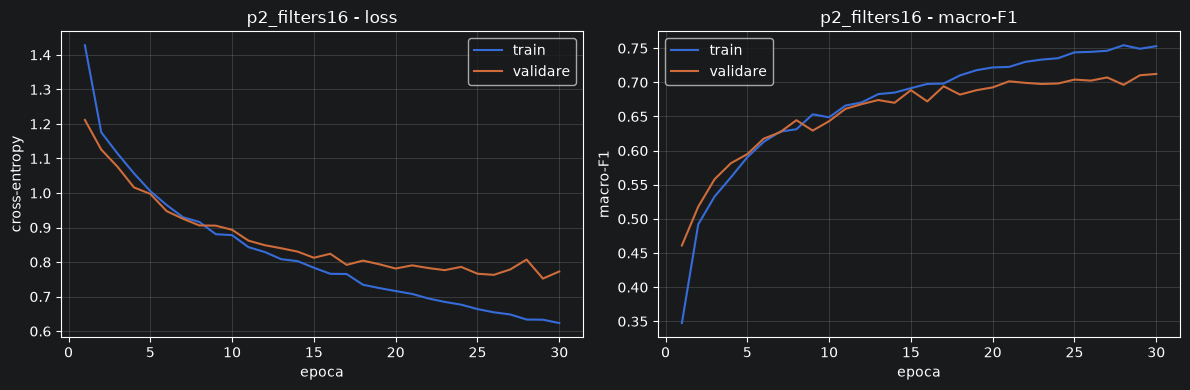

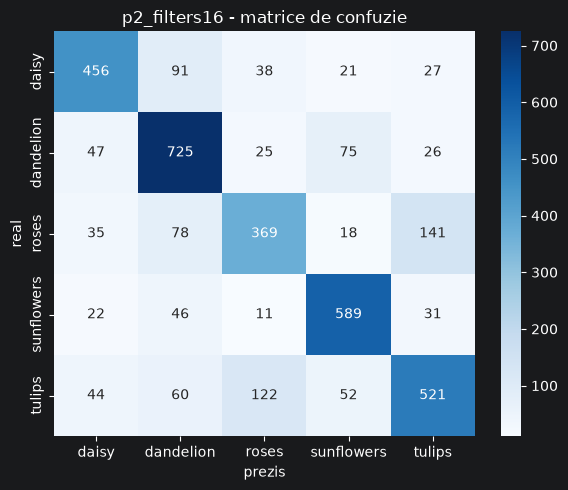


 p2_depth4_nopool


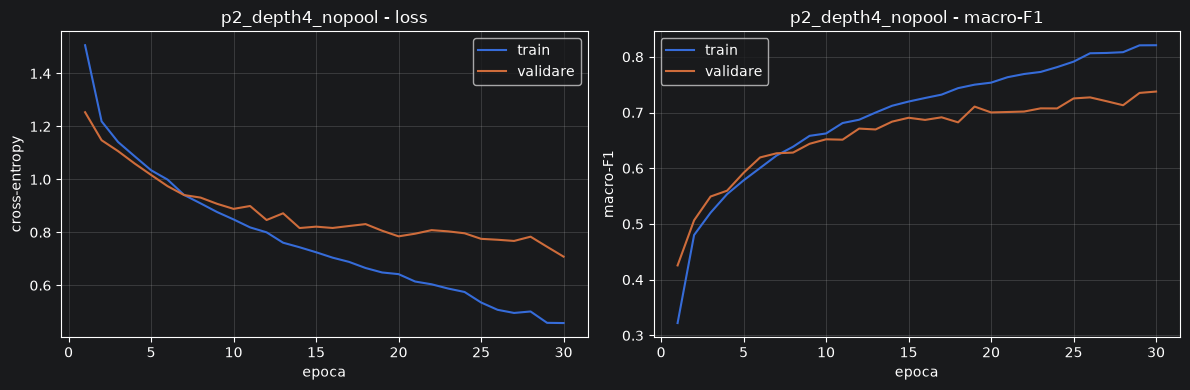

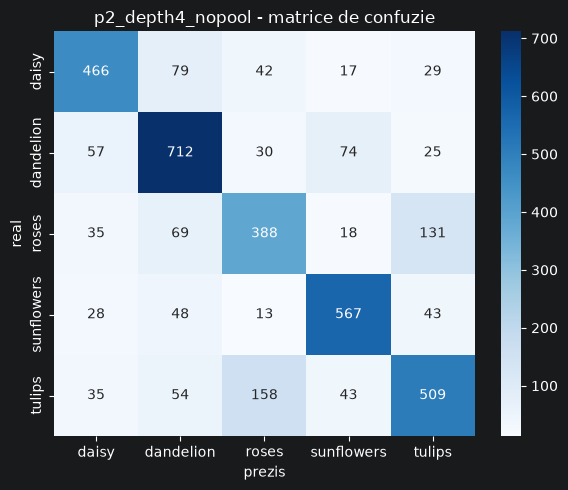


 p2_depth5_nopool


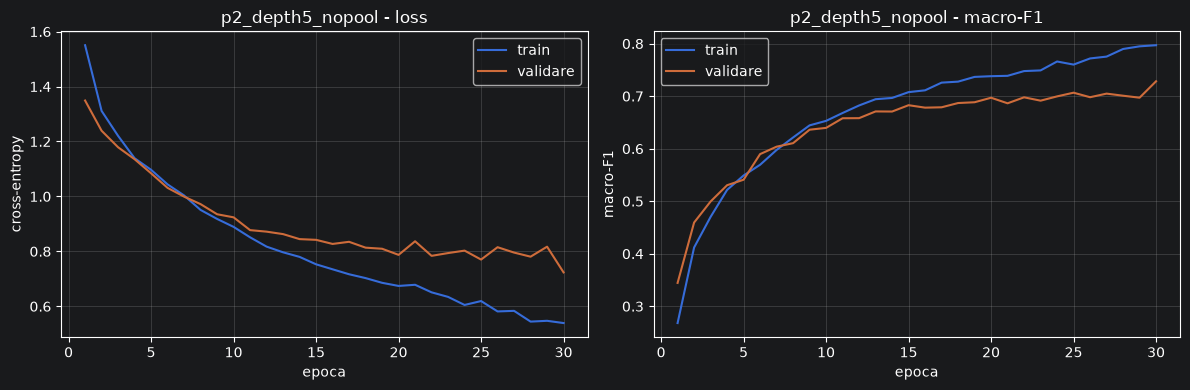

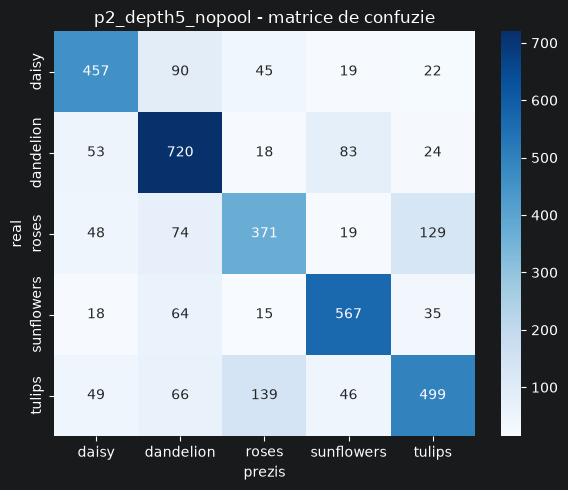


 p2_depth2_nopool


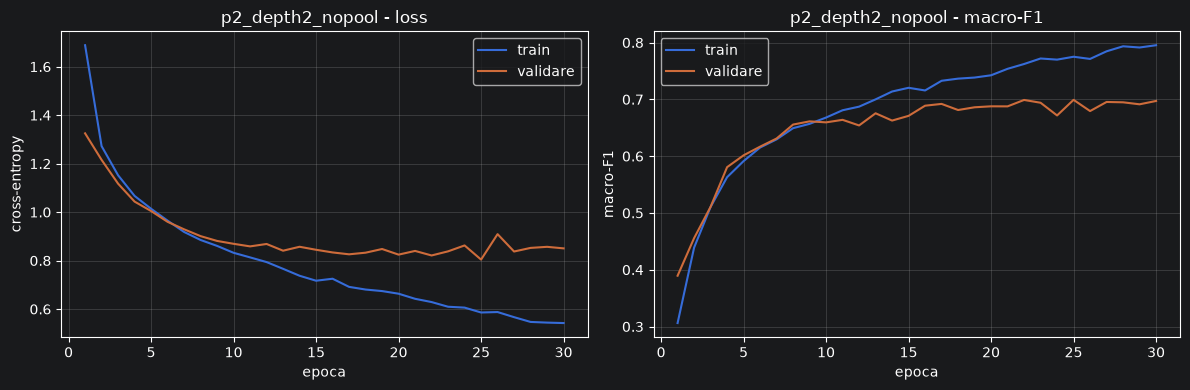

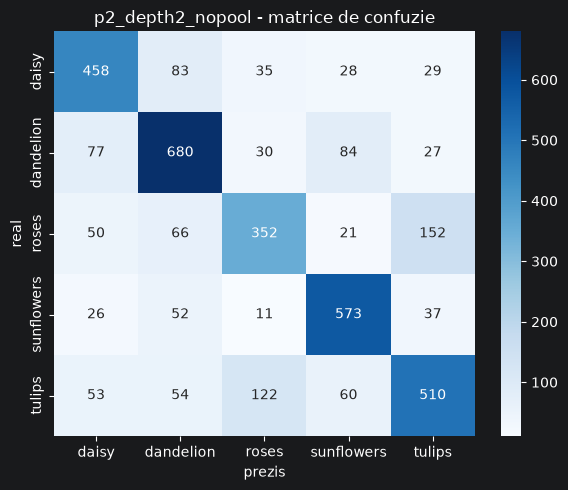


 p2_depth1_maxpool


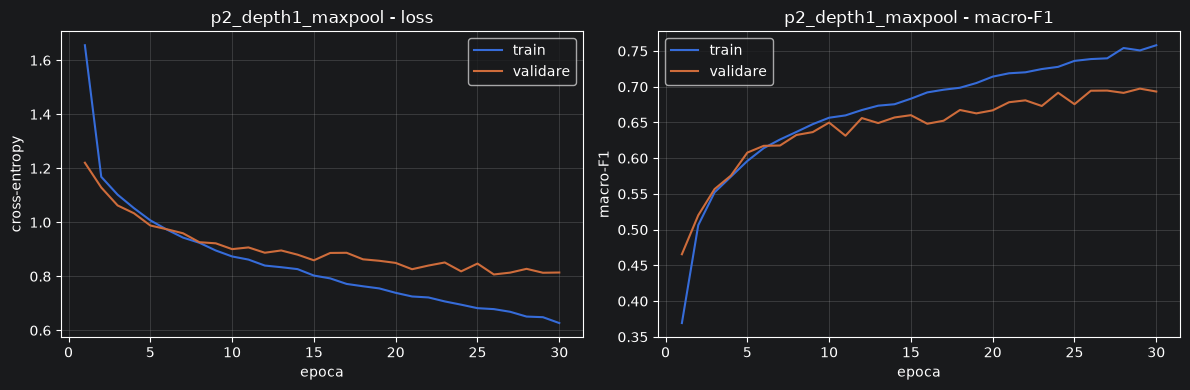

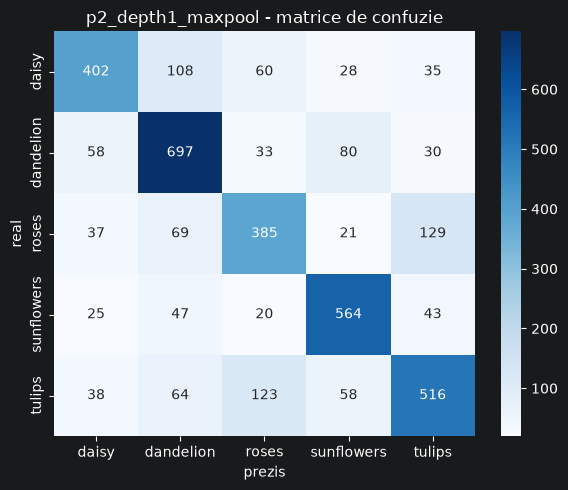


 p2_depth1_nopool


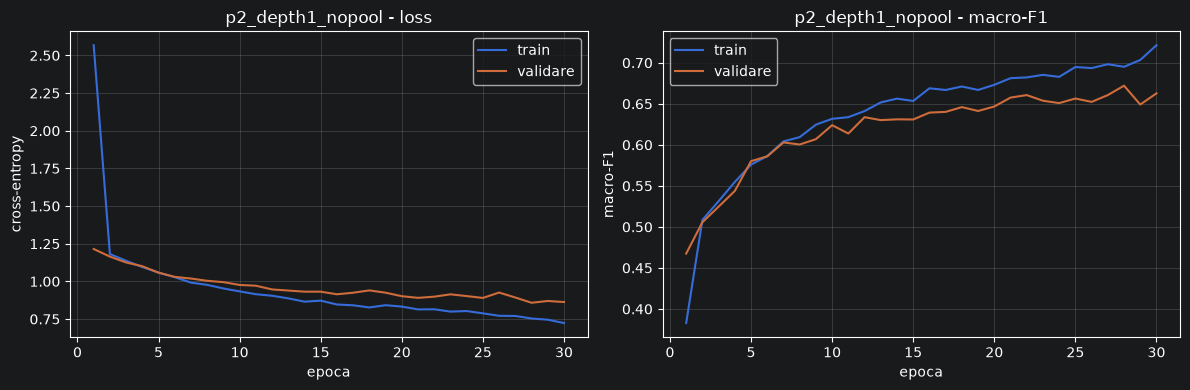

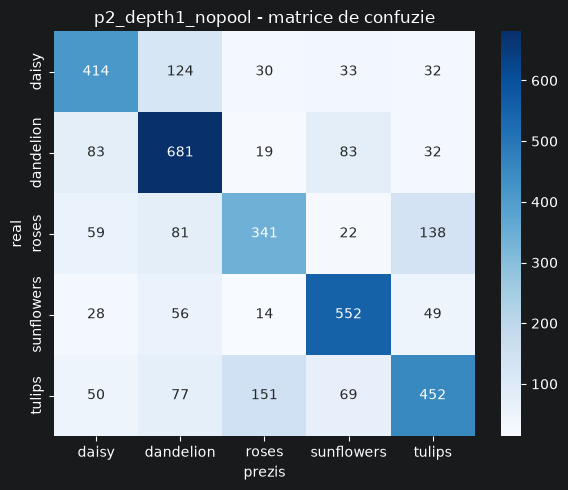

In [6]:
for name in p2_results["name"]:
    print("\n", name)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    lab4_common.plot_history(name, ax=axes)
    plt.show()

    fig, ax = plt.subplots(figsize=(6, 5))
    lab4_common.plot_confusion(name, ax=ax, normalize=False)
    plt.show()

## 10. Interpretarea rezultatelor și alegerea arhitecturii pentru Partea 3

Celula următoare selectează configurația cu cel mai mare macro-F1 mediu pe cele 5 fold-uri și salvează configurația în `results/lab4/part2_selected_architecture.json`.

Interpretarea trebuie să țină cont și de:
- deviația standard a macro-F1 între fold-uri (stabilitatea);
- numărul de parametri și dimensiunea pe disc;
- timpul de antrenare;
- curbele loss/F1 (convergență și eventual overfitting);
- matricea de confuzie (clasele confundate).

Nu se adaugă aici experimente de regularizare, dropout, batch normalization, learning rate sau comparații CPU/GPU: acestea sunt cerințe ale Părții 3 sau ale cerințelor generale repartizate separat.

In [7]:
best = p2_results.sort_values(
    ["val_f1_mean", "val_f1_std"],
    ascending=[False, True]
).iloc[0]

best_name = best["name"]
best_config_path = lab4_common.OUT_DIR / "runs" / best_name / "config.json"
best_config = json.loads(best_config_path.read_text(encoding="utf-8"))

selected_architecture = {
    "experiment": best_name,
    "config": best_config,
    "selection_rule": "macro-F1 mediu maxim pe cele 5 fold-uri; la egalitate, deviație standard mai mică",
    "val_f1_mean": float(best["val_f1_mean"]),
    "val_f1_std": float(best["val_f1_std"]),
    "n_params": int(best["n_params"]),
    "model_mb": float(best["model_mb"]),
    "train_minutes_total": float(best["train_minutes_total"]),
}

selection_path = lab4_common.OUT_DIR / "part2_selected_architecture.json"
selection_path.write_text(
    json.dumps(selected_architecture, indent=2),
    encoding="utf-8"
)

print("Arhitectura selectată pentru Partea 3:")
display(pd.Series({
    "experiment": best_name,
    "macro-F1 mediu": selected_architecture["val_f1_mean"],
    "deviație standard": selected_architecture["val_f1_std"],
    "număr parametri": selected_architecture["n_params"],
    "dimensiune model (MB)": selected_architecture["model_mb"],
    "timp total (minute)": selected_architecture["train_minutes_total"],
}))
print("\nConfigurație:")
print(json.dumps(best_config, indent=2))
print("\nSalvat în:", selection_path)

Arhitectura selectată pentru Partea 3:


experiment               p2_filters64
macro-F1 mediu               0.766696
deviație standard            0.011932
număr parametri                600709
dimensiune model (MB)        2.295796
timp total (minute)           6.00805
dtype: object


Configurație:
{
  "name": "p2_filters64",
  "img_size": 64,
  "conv_layers": [
    64,
    64,
    64
  ],
  "kernel_size": 3,
  "stride": 1,
  "pooling": "max",
  "recurrent": null,
  "rnn_hidden": 128,
  "fc_layers": [
    128
  ],
  "activation": "relu",
  "batch_norm": false,
  "dropout": 0.0,
  "augment": true,
  "optimizer": "adam",
  "lr": 0.001,
  "weight_decay": 0.0,
  "l1": 0.0,
  "batch_size": 64,
  "epochs": 30,
  "patience": 5
}

Salvat în: D:\uni_ 3\ML\lab_1\results\lab4\part2_selected_architecture.json


## 11. Fișiere produse de infrastructura comună

Pentru fiecare experiment complet, `lab4_common.py` salvează:
- `results/lab4/runs/<nume>/config.json` – configurația;
- `fold0.json` … `fold4.json` – rezultatele fiecărui fold;
- `history.csv` – loss și macro-F1 train/validation pe epoci;
- `predictions.csv` – predicțiile out-of-fold pentru fiecare imagine;
- `results/lab4/models/<nume>.pt` – modelul salvat pentru fold-ul 0, folosit și la măsurarea dimensiunii pe disc.

În plus, notebook-ul salvează `results/lab4/part2_selected_architecture.json`, cu arhitectura aleasă pentru Partea 3.

**Finalizare:** Partea 2 este acoperită după ce toate experimentele din secțiunile 3–6 au câte 5 fold-uri terminate, iar tabelele, graficele și matricile de confuzie au fost inspectate.